# CUBIT Model

This notebook explores the possibility of integrating a frequency dependent capacitor to produce a qubit that employs a non-linear capacitor (coined CUBIT in [1]). The data come from the graphene nanocapacitors of [2], whose capacitance changes with frequency (Fig. 7 of [2]). A qubit needs unequally spaced energy levels, which a nonlinear element provides, so the question here is whether this frequency dependence can supply that nonlinearity. I start by modeling the frequency dependence.

## Nanocapacitor Data from Bezryadin et al. [2]

First, the data from Fig. 7 [2, Fig. 7] was obtained from WebPlotDigitizer [3]. It gives the capacitance (nF) against frequency (kHz) for two devices, `S2_3-4` and `S2_2-3`, each saved as a CSV file in `data/`. In the next block, I plot the datasets `S2_3-4` and `S2_2-3` and compare them to Fig. 7 [2, Fig. 7]. The output shows a side-by-side comparison of the figure from [2] (left) with the data from the WPD (right). The two plots should have agreement on the plateaus, the position of the knee, and which curve sits to the right. The points were digitised by hand, so they carry an error of a few percent.

In [4]:
import matplotlib.pyplot as plt
import matplotlib.cbook as cbook

import numpy as np
import pandas as pd

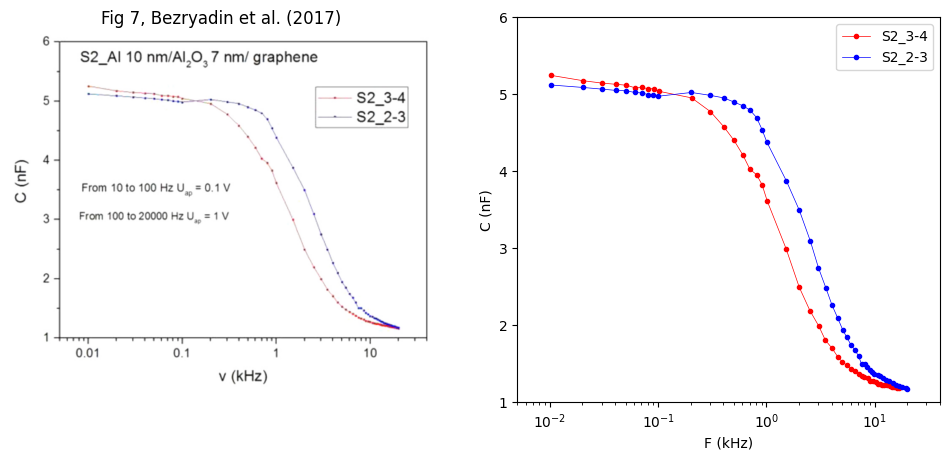

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Read in the datasets
s2_34 = pd.read_csv("data/S2_3-4.csv", header=None, names=["f_kHz", "C_nF"])
s2_23 = pd.read_csv("data/S2_2-3.csv", header=None, names=["f_kHz", "C_nF"])

x_34, y_34 = s2_34["f_kHz"], s2_34["C_nF"]
x_23, y_23 = s2_23["f_kHz"], s2_23["C_nF"]

# Image of Fig 7 from the paper
img = Image.open("figures/S2-3_4_2-3.jpg")

# Image on the left, data on the right
fig, (ax_img, ax_data) = plt.subplots(1, 2, figsize=(12, 5))

ax_img.imshow(img)
ax_img.axis("off")
ax_img.set_title("Fig 7, Bezryadin et al. (2017)")

ax_data.plot(x_34, y_34, "o-", linewidth=0.5, label="S2_3-4", color="red", ms=3)
ax_data.plot(x_23, y_23, "o-", linewidth=0.5, label="S2_2-3", color="blue", ms=3)

ax_data.set_xscale("log")
ax_data.set(xlim=(0.005, 40), ylim=(1, 6))
ax_data.set(xlabel="F (kHz)", ylabel="C (nF)")
ax_data.legend()

plt.show()

## Debye Model

We model the capacitor as a Debye capacitor [4, Sec. 3.3; 5, Ch. 1]: with an instantaneous response and a single slow process,

$$C(f)=C_\infty+\frac{\Delta C}{1+(2\pi f\tau)^2}.$$

We can curve fit this model to get the effective parameters of this experiment: $C_\infty$, the baseline/instantaneous capacitance, $\Delta C$, the extra capacitance added by the slow process, and $\tau$, the relaxation time constant. The fit uses `curve_fit` from SciPy [6], and fits $\log_{10}\tau$ instead of $\tau$ (so that all three parameters are of order 1).

Run the block below to get curve fitted values that used results from both datasets `S2_2-3` and `S2_3-4`. Since this fit pools them, it assumes the two devices are identical. The fits of each dataset on its own come later.

In [6]:
from scipy.optimize import curve_fit
from models import DebyeCapacitor

# define the model function

def debye_for_curve_fit(f, c_inf, del_c, log_tau):
    result = DebyeCapacitor(c_inf, del_c, 10 ** log_tau).computeCapacitance(f)
    return result

f_Hz_comb = np.concatenate([x_23 * 1000, x_34 * 1000])
y_nF_comb = np.concatenate([y_23, y_34])

popt, pcov = curve_fit(debye_for_curve_fit, f_Hz_comb, y_nF_comb)

c_inf, del_c, log_tau = popt
sig_c_inf, sig_del_c, sig_log_tau = np.sqrt(np.diag(pcov))

tau = 10 ** log_tau                        # seconds
sig_tau = tau * np.log(10) * sig_log_tau   # propagate the log10 error

print("Debye Fit")
print("--------------------")
print(f"C_inf : {c_inf:.3f} ± {sig_c_inf:.3f} nF")
print(f"del_C : {del_c:.3f} ± {sig_del_c:.3f} nF")
print(f"tau   : {tau * 1e6:.1f} ± {sig_tau * 1e6:.1f} µs")

Debye Fit
--------------------
C_inf : 1.207 ± 0.040 nF
del_C : 3.812 ± 0.053 nF
tau   : 85.5 ± 3.7 µs


We were able to obtain values and uncertainties for the respective parameters. The uncertainties are a lower bound. To check that our result matches up, we can plot curves using our fitted values against the original data. 

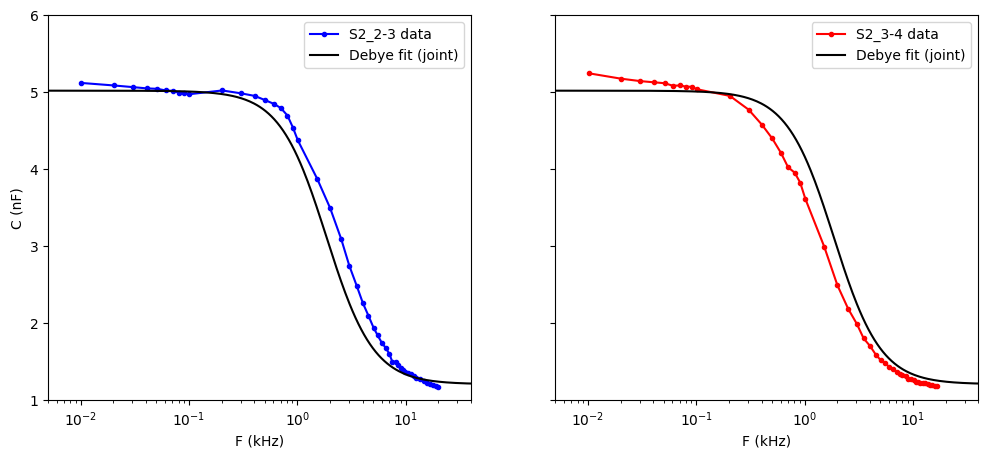

In [7]:
f_grid = np.logspace(-2.3, 1.7, 300)    # kHz
y_fit = DebyeCapacitor(c_inf, del_c, tau).computeCapacitance(f_grid * 1000)

fig, (ax_23, ax_34) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

ax_23.plot(x_23, y_23, "o-", ms=3, color="blue", label="S2_2-3 data")
ax_23.plot(f_grid, y_fit, "-", color="black", label="Debye fit (joint)")

ax_34.plot(x_34, y_34, "o-", ms=3, color="red", label="S2_3-4 data")
ax_34.plot(f_grid, y_fit, "-", color="black", label="Debye fit (joint)")

for ax in (ax_23, ax_34):
    ax.set_xscale("log")
    ax.set(xlim=(0.005, 40), ylim=(1, 6), xlabel="F (kHz)")
    ax.legend()
ax_23.set_ylabel("C (nF)")

plt.show()

We can also compute the residuals, defined as the data minus the model, by evaluating the fitted curve at the frequency of each data point and subtracting it from the measured capacitance. The plot below shows the data against the pooled fit (top) and the residuals (bottom) for each sample.

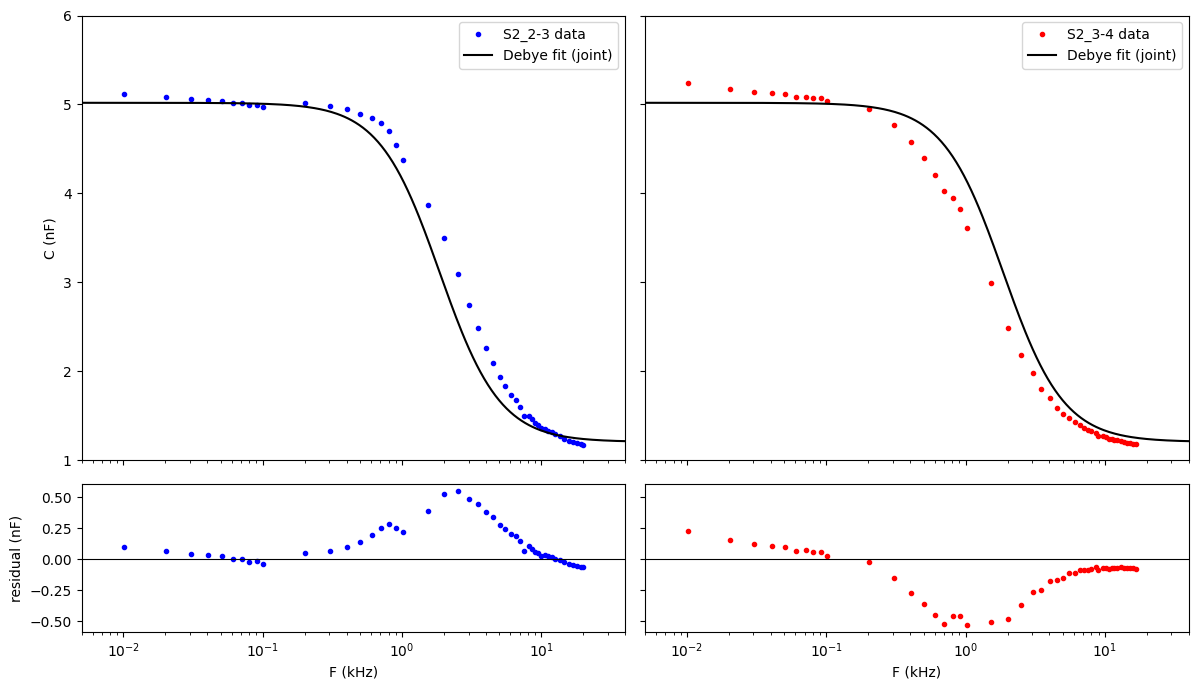

In [8]:
from numpy.typing import ArrayLike

def computeResiduals(y_data: ArrayLike, y_model: ArrayLike):
    """Return the residuals, data minus model, in the same units as the inputs."""
    return y_data - y_model

model = DebyeCapacitor(c_inf, del_c, tau)

y_fit_23 = model.computeCapacitance(x_23 * 1000)
y_fit_34 = model.computeCapacitance(x_34 * 1000)

res_23 = computeResiduals(y_23, y_fit_23)
res_34 = computeResiduals(y_34, y_fit_34)

fig, axes = plt.subplots(
    2, 2, figsize=(12, 7), sharex=True, sharey="row",
    gridspec_kw={"height_ratios": [3, 1]},
)
(ax_23, ax_34), (ax_r23, ax_r34) = axes

# top row: data against the fitted curve
ax_23.plot(x_23, y_23, "o", ms=3, color="blue", label="S2_2-3 data")
ax_23.plot(f_grid, y_fit, "-", color="black", label="Debye fit (joint)")

ax_34.plot(x_34, y_34, "o", ms=3, color="red", label="S2_3-4 data")
ax_34.plot(f_grid, y_fit, "-", color="black", label="Debye fit (joint)")

# bottom row: residuals (data - model)
ax_r23.plot(x_23, res_23, "o", ms=3, color="blue")
ax_r34.plot(x_34, res_34, "o", ms=3, color="red")

for ax in (ax_r23, ax_r34):
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xlabel="F (kHz)")

for ax in (ax_23, ax_34):
    ax.legend()

ax_23.set_xscale("log")                 # shared, so this sets all four
ax_23.set(xlim=(0.005, 40), ylim=(1, 6), ylabel="C (nF)")
ax_r23.set(ylabel="residual (nF)")

fig.tight_layout()
plt.show()

To put a single number on how well the pooled curve fits, we take the root-mean-square (RMS) of the residuals for each sample, $\text{RMS}=\sqrt{\tfrac{1}{N}\sum_i r_i^2}$, where $r_i$ is the residual at point $i$ and $N$ is the number of points. The pooled RMS is the same quantity over both samples together, so it should land between the two individual values.

In [14]:
# compute joint fit rms

rms_23 = np.sqrt(np.sum(res_23 ** 2) / len(res_23))
rms_34 = np.sqrt(np.sum(res_34 ** 2) / len(res_34))

pooled_size = len(res_23) + len(res_34)


pooled_rms = np.sqrt((1/pooled_size) * (
    len(res_23) * (rms_23 ** 2) + len(res_34) * (rms_34 ** 2)
))

# Check accuracy: pooled rms must be between the two RMS

print("Joint fit RMS residuals")
print("-----------------------")
print(f"S2_2-3 : {rms_23:.3f} nF")
print(f"S2_3-4 : {rms_34:.3f} nF")
print(f"Pooled : {pooled_rms:.3f} nF")

# Check: the pooled RMS must lie between the two per-sample values
expected_rms_bool = min(rms_23, rms_34) <= pooled_rms <= max(rms_23, rms_34)
print(f"\nPooled RMS between the two: {expected_rms_bool}")

Joint fit RMS residuals
-----------------------
S2_2-3 : 0.207 nF
S2_3-4 : 0.230 nF
Pooled : 0.219 nF

Pooled RMS between the two: True


## Debye Fits of Each Sample

The residuals from the pooled fit show that a single Debye curve misses both devices in opposite directions around the knee, so the two devices do not share the same parameters. We can also run the same kind of curve fit on each sample on its own, to see the accuracy of their own Debye curves. We can then compare the RMS from the pooled result above with the RMS of each sample. The process that follows is essentially the same as the one above, with a few changes: the fit is done once per sample, the pooled values are used as the starting guess `p0`.

For each sample, the fit gives $C_\infty$, $\Delta C$, $\tau$ with their uncertainties, and the RMS residual. As before, the uncertainties are a lower bound, since they assume the Debye model is right and do not include the digitising error.

In [10]:
p0_vals = [1.207, 3.812, np.log10(85.5e-6)]     # taken from our original combined fit

samples = [
    # name,    f (kHz), C (nF), p0 = [c_inf, del_c, log_tau]
    ("S2_2-3", x_23, y_23, p0_vals),
    ("S2_3-4", x_34, y_34, p0_vals),
]

results = []
for name, x, y, p0 in samples:
    f_Hz = x * 1000

    s_popt, s_pcov = curve_fit(debye_for_curve_fit, f_Hz, y, p0=p0)
    s_c_inf, s_del_c, s_log_tau = s_popt
    s_sig_c_inf, s_sig_del_c, s_sig_log_tau = np.sqrt(np.diag(s_pcov))

    s_tau = 10 ** s_log_tau
    s_sig_tau = s_tau * np.log(10) * s_sig_log_tau

    residuals = y - DebyeCapacitor(s_c_inf, s_del_c, s_tau).computeCapacitance(f_Hz)
    s_rms = np.sqrt(np.mean(residuals ** 2))

    print(f"Debye fit: {name}")
    print("--------------------")
    print(f"C_inf : {s_c_inf:.3f} ± {s_sig_c_inf:.3f} nF")
    print(f"del_C : {s_del_c:.3f} ± {s_sig_del_c:.3f} nF")
    print(f"tau   : {s_tau * 1e6:.1f} ± {s_sig_tau * 1e6:.1f} µs")
    print(f"RMS   : {s_rms:.3f} nF\n")

    results.append({
        "sample": name, "C_inf": s_c_inf, "del_C": s_del_c, "tau": s_tau,
        "sig_C_inf": s_sig_c_inf, "sig_del_C": s_sig_del_c, "sig_tau": s_sig_tau,
        "rms": s_rms,
    })

Debye fit: S2_2-3
--------------------
C_inf : 1.143 ± 0.011 nF
del_C : 3.891 ± 0.013 nF
tau   : 63.3 ± 0.6 µs
RMS   : 0.036 nF

Debye fit: S2_3-4
--------------------
C_inf : 1.225 ± 0.020 nF
del_C : 3.836 ± 0.030 nF
tau   : 120.2 ± 2.8 µs
RMS   : 0.085 nF



The fits give $\tau$ = 63.3 ± 0.6 µs for S2_2-3 and 120.2 ± 2.8 µs for S2_3-4, with an RMS of 0.036 nF and 0.085 nF. To see how these compare with the pooled fit, we plot each sample against both curves: the pooled fit in grey and the sample's own fit in black. The residuals below each panel are for the separate fit, on the same $\pm0.6$ nF scale as the pooled residuals earlier.

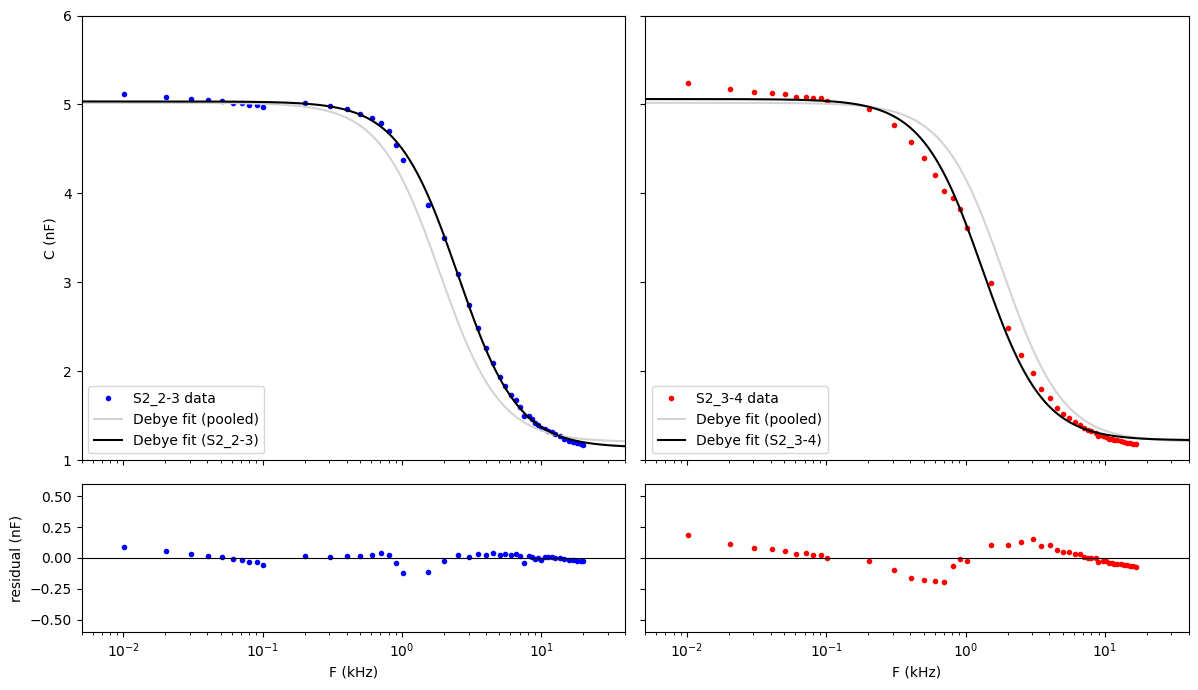

In [11]:
# each sample's fitted parameters, looked up by name from the loop's results
by_name = {r["sample"]: r for r in results}

samples = [
    # name,    f (kHz), C (nF), colour
    ("S2_2-3", x_23, y_23, "blue"),
    ("S2_3-4", x_34, y_34, "red"),
]

fig, axes = plt.subplots(
    2, 2, figsize=(12, 7), sharex=True, sharey="row",
    gridspec_kw={"height_ratios": [3, 1]},
)

for col, (name, x, y, color) in enumerate(samples):
    r = by_name[name]
    s_model = DebyeCapacitor(r["C_inf"], r["del_C"], r["tau"])
    s_curve = s_model.computeCapacitance(f_grid * 1000)                     # smooth curve
    s_res = computeResiduals(y, s_model.computeCapacitance(x * 1000))       # at the data

    ax_top, ax_res = axes[0, col], axes[1, col]

    # top row: data, pooled fit (grey), this sample's own fit (black)
    ax_top.plot(x, y, "o", ms=3, color=color, label=f"{name} data")
    ax_top.plot(f_grid, y_fit, "-", color="lightgrey", label="Debye fit (pooled)")
    ax_top.plot(f_grid, s_curve, "-", color="black", label=f"Debye fit ({name})")
    ax_top.legend(loc="lower left")

    # bottom row: residuals of the separate fit (data - model)
    ax_res.plot(x, s_res, "o", ms=3, color=color)
    ax_res.axhline(0, color="black", linewidth=0.8)
    ax_res.set(xlabel="F (kHz)")

axes[0, 0].set_xscale("log")            # shared, so this sets all four
axes[0, 0].set(xlim=(0.005, 40), ylim=(1, 6), ylabel="C (nF)")
axes[1, 0].set(ylabel="residual (nF)", ylim=(-0.6, 0.6))

fig.tight_layout()
plt.show()

As visible in the graph and results above, the simple Debye capacitor model fits S2_2-3 much better than S2_3-4: S2_2-3 obtains a residual RMS of 0.036 nF, compared to more than twice that (0.085 nF) for S2_3-4. The S2_3-4 residuals also have a systematic shape instead of random scatter, which suggests that its step is broader than a single relaxation time allows. This means there might be an advantage in modeling S2_3-4 with a Cole-Cole extension [7] of the simple Debye capacitor, which adds one parameter that broadens the step and reduces to the Debye model when it is zero. We can also use the extended model to examine whether a Cole-Cole fit improves the fitting of the first sample, S2_2-3.

In [15]:
from models import ColeColeCapacitor

def cole_cole_for_curve_fit(f, c_inf, del_c, log_tau, alpha):
    return ColeColeCapacitor(c_inf, del_c, 10 ** log_tau, alpha).computeCapacitance(f)

debye_by_name = {r["sample"]: r for r in results}     # per-sample Debye results

data_cc = [
    ("S2_2-3", x_23, y_23),
    ("S2_3-4", x_34, y_34),
]

results_cc = []
for name, x, y in data_cc:
    d = debye_by_name[name]
    f_Hz = x * 1000

    # start from the Debye fit, with a small broadening
    cc_p0 = [d["C_inf"], d["del_C"], np.log10(d["tau"]), 0.1]

    cc_popt, cc_pcov = curve_fit(
        cole_cole_for_curve_fit, f_Hz, y, p0=cc_p0,
        bounds=([0, 0, -6, 0], [np.inf, np.inf, -2, 0.9]),
    )
    cc_c_inf, cc_del_c, cc_log_tau, cc_alpha = cc_popt
    cc_sig_c_inf, cc_sig_del_c, cc_sig_log_tau, cc_sig_alpha = np.sqrt(np.diag(cc_pcov))

    cc_tau = 10 ** cc_log_tau
    cc_sig_tau = cc_tau * np.log(10) * cc_sig_log_tau

    cc_model = ColeColeCapacitor(cc_c_inf, cc_del_c, cc_tau, cc_alpha)
    cc_res = y - cc_model.computeCapacitance(f_Hz)
    cc_rms = np.sqrt(np.mean(cc_res ** 2))

    print(f"Cole-Cole fit: {name}")
    print("--------------------")
    print(f"C_inf : {cc_c_inf:.3f} ± {cc_sig_c_inf:.3f} nF")
    print(f"del_C : {cc_del_c:.3f} ± {cc_sig_del_c:.3f} nF")
    print(f"tau   : {cc_tau * 1e6:.1f} ± {cc_sig_tau * 1e6:.1f} µs")
    print(f"alpha : {cc_alpha:.3f} ± {cc_sig_alpha:.3f}")
    print(f"RMS   : {cc_rms:.3f} nF   (Debye: {d['rms']:.3f} nF)\n")

    results_cc.append({
        "sample": name, "C_inf": cc_c_inf, "del_C": cc_del_c, "tau": cc_tau,
        "alpha": cc_alpha, "sig_C_inf": cc_sig_c_inf, "sig_del_C": cc_sig_del_c,
        "sig_tau": cc_sig_tau, "sig_alpha": cc_sig_alpha,
        "rms": cc_rms, "rms_debye": d["rms"],
    })

Cole-Cole fit: S2_2-3
--------------------
C_inf : 1.096 ± 0.016 nF
del_C : 3.957 ± 0.022 nF
tau   : 63.0 ± 0.6 µs
alpha : 0.022 ± 0.006
RMS   : 0.031 nF   (Debye: 0.036 nF)

Cole-Cole fit: S2_3-4
--------------------
C_inf : 1.059 ± 0.014 nF
del_C : 4.101 ± 0.020 nF
tau   : 116.4 ± 1.1 µs
alpha : 0.097 ± 0.006
RMS   : 0.029 nF   (Debye: 0.085 nF)



The Cole-Cole fits give $\alpha$ = 0.022 ± 0.006 for S2_2-3 and 0.097 ± 0.006 for S2_3-4, with RMS values of 0.031 nF and 0.029 nF. To see where the extra parameter makes a difference, we plot each sample against its own Debye fit and its own Cole-Cole fit, with the residuals of both models underneath on the same $\pm0.6$ nF scale as before.

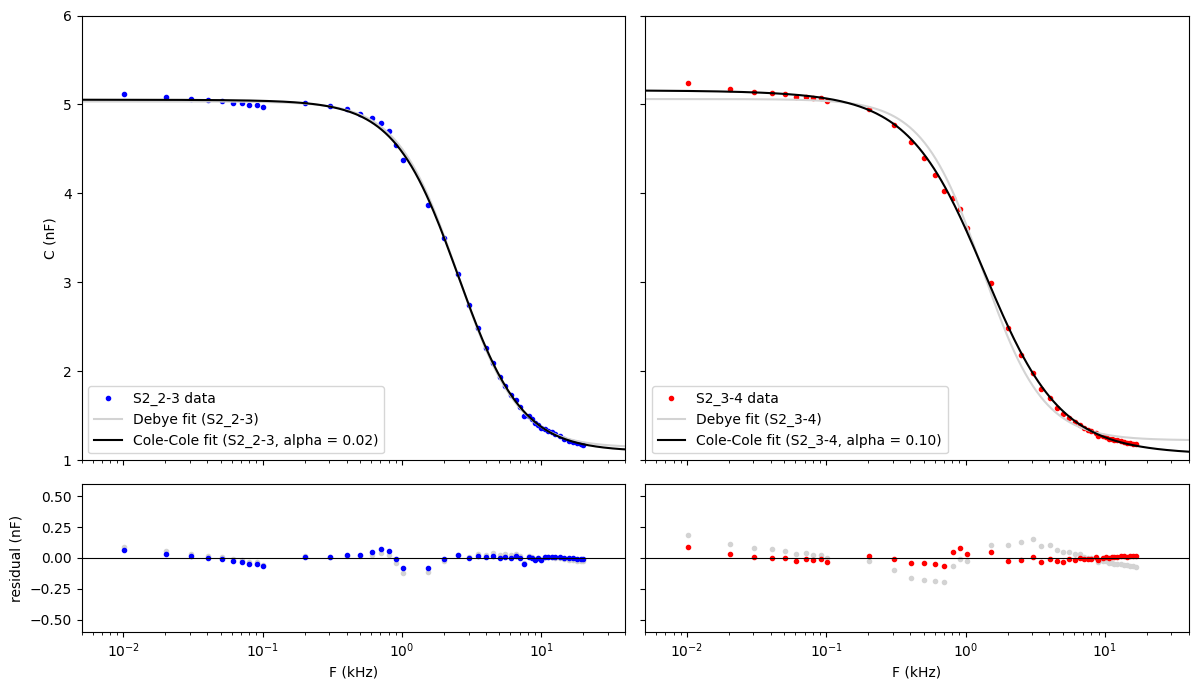

In [17]:
# each sample's fitted parameters, look up by name
debye_by_name = {r["sample"]: r for r in results}
cc_by_name = {r["sample"]: r for r in results_cc}

plot_samples = [
    # name,    f (kHz), C (nF), colour
    ("S2_2-3", x_23, y_23, "blue"),
    ("S2_3-4", x_34, y_34, "red"),
]

fig, axes = plt.subplots(
    2, 2, figsize=(12, 7), sharex=True, sharey="row",
    gridspec_kw={"height_ratios": [3, 1]},
)

for col, (name, x, y, color) in enumerate(plot_samples):
    d, c = debye_by_name[name], cc_by_name[name]
    d_model = DebyeCapacitor(d["C_inf"], d["del_C"], d["tau"])
    c_model = ColeColeCapacitor(c["C_inf"], c["del_C"], c["tau"], c["alpha"])

    d_curve = d_model.computeCapacitance(f_grid * 1000)                  # smooth curves
    c_curve = c_model.computeCapacitance(f_grid * 1000)
    d_res = computeResiduals(y, d_model.computeCapacitance(x * 1000))    # at the data
    c_res = computeResiduals(y, c_model.computeCapacitance(x * 1000))

    ax_top, ax_res = axes[0, col], axes[1, col]

    # top row: data, Debye fit (light grey), Cole-Cole fit (black)
    ax_top.plot(x, y, "o", ms=3, color=color, label=f"{name} data")
    ax_top.plot(f_grid, d_curve, "-", color="lightgrey", label=f"Debye fit ({name})")
    ax_top.plot(f_grid, c_curve, "-", color="black",
                label=f"Cole-Cole fit ({name}, alpha = {c['alpha']:.2f})")
    ax_top.legend(loc="lower left")

    # bottom row: residuals (data - model); Debye in grey, Cole-Cole in colour
    ax_res.plot(x, d_res, "o", ms=3, color="lightgrey")
    ax_res.plot(x, c_res, "o", ms=3, color=color)
    ax_res.axhline(0, color="black", linewidth=0.8)
    ax_res.set(xlabel="F (kHz)")

axes[0, 0].set_xscale("log")            # shared, so this sets all four
axes[0, 0].set(xlim=(0.005, 40), ylim=(1, 6), ylabel="C (nF)")
axes[1, 0].set(ylabel="residual (nF)", ylim=(-0.6, 0.6))

fig.tight_layout()
plt.show()

To check that the broadening of S2_3-4 is not an artifact of the instrument being switched at 100 Hz (lock-in at 0.1 V below, LCR meter at 1 V above), we refit using only the points above 100 Hz. $\alpha$ changes from 0.097 to 0.085 ± 0.007 and $\tau$ from 116.4 to 114.4 µs, with the RMS unchanged (0.026 vs 0.028 nF), and S2_2-3 does not change at all. The broadening is therefore present in the LCR-meter data alone.

In [21]:
mask_23 = x_23 > 0.1
mask_34 = x_34 > 0.1

x_23_fil, y_23_fil = x_23[mask_23], y_23[mask_23]
x_34_fil, y_34_fil = x_34[mask_34], y_34[mask_34]

data_fil = [
    ("S2_2-3", x_23_fil, y_23_fil),
    ("S2_3-4", x_34_fil, y_34_fil),
]

results_fil = []
for name, x, y in data_fil:
    f_Hz = x * 1000
    full = cc_by_name[name]          # Cole-Cole fit on the full range

    # start from the full-range Cole-Cole result
    fil_p0 = [full["C_inf"], full["del_C"], np.log10(full["tau"]), full["alpha"]]

    fil_popt, fil_pcov = curve_fit(
        cole_cole_for_curve_fit, f_Hz, y, p0=fil_p0,
        bounds=([0, 0, -6, 0], [np.inf, np.inf, -2, 0.9]),
    )
    fil_c_inf, fil_del_c, fil_log_tau, fil_alpha = fil_popt
    fil_sig_c_inf, fil_sig_del_c, fil_sig_log_tau, fil_sig_alpha = np.sqrt(np.diag(fil_pcov))

    fil_tau = 10 ** fil_log_tau
    fil_sig_tau = fil_tau * np.log(10) * fil_sig_log_tau

    fil_model = ColeColeCapacitor(fil_c_inf, fil_del_c, fil_tau, fil_alpha)
    fil_rms = np.sqrt(np.mean((y - fil_model.computeCapacitance(f_Hz)) ** 2))

    # full-range model, scored on the same filtered points
    full_model = ColeColeCapacitor(full["C_inf"], full["del_C"], full["tau"], full["alpha"])
    full_rms_on_fil = np.sqrt(np.mean((y - full_model.computeCapacitance(f_Hz)) ** 2))

    print(f"Cole-Cole, f > 100 Hz vs full range: {name}  ({len(x)} points)")
    print("--------------------")
    print(f"tau   : {fil_tau * 1e6:.1f} ± {fil_sig_tau * 1e6:.1f} µs   (full: {full['tau'] * 1e6:.1f} µs)")
    print(f"alpha : {fil_alpha:.3f} ± {fil_sig_alpha:.3f}   (full: {full['alpha']:.3f})")
    print(f"RMS   : {fil_rms:.3f} nF   (full-range model on these points: {full_rms_on_fil:.3f} nF)\n")

    results_fil.append({
        "sample": name, "C_inf": fil_c_inf, "del_C": fil_del_c, "tau": fil_tau,
        "alpha": fil_alpha, "sig_C_inf": fil_sig_c_inf, "sig_del_C": fil_sig_del_c,
        "sig_tau": fil_sig_tau, "sig_alpha": fil_sig_alpha, "rms": fil_rms,
    })

Cole-Cole, f > 100 Hz vs full range: S2_2-3  (39 points)
--------------------
tau   : 63.2 ± 0.6 µs   (full: 63.0 µs)
alpha : 0.024 ± 0.007   (full: 0.022)
RMS   : 0.030 nF   (full-range model on these points: 0.030 nF)

Cole-Cole, f > 100 Hz vs full range: S2_3-4  (38 points)
--------------------
tau   : 114.4 ± 1.2 µs   (full: 116.4 µs)
alpha : 0.085 ± 0.007   (full: 0.097)
RMS   : 0.026 nF   (full-range model on these points: 0.028 nF)



The Cole-Cole fits above are repeated using only the points above 100 Hz (39 points for S2_2-3 and 38 for S2_3-4). This is where the measurement changes instrument and drive amplitude, from the lock-in at 0.1 V below to the LCR meter at 1 V above, so a fit that depends on the switch would change here. It does not. For S2_2-3, $\alpha$ = 0.024 ± 0.007 and $\tau$ = 63.2 ± 0.6 µs, against 0.022 and 63.0 µs for the full range, with the same RMS (0.030 nF). For S2_3-4, $\alpha$ goes from 0.097 to 0.085 ± 0.007, $\tau$ from 116.4 to 114.4 µs, and the RMS from 0.028 to 0.026 nF on the same points. That is a drift of under two quoted uncertainties, and these are lower bounds, so we do not read it as a change. The broadening of S2_3-4 is therefore present in the LCR-meter data alone and does not come from the lock-in points or the instrument switch. This only tests the switch as a whole: the instrument and the drive amplitude change together at 100 Hz, so it cannot tell us whether the amplitude itself matters.

In [27]:
debye_by_name = {r["sample"]: r for r in results}
cc_by_name = {r["sample"]: r for r in results_cc}
fil_by_name = {r["sample"]: r for r in results_fil}

pooled = {"C_inf": c_inf, "sig_C_inf": sig_c_inf, "del_C": del_c, "sig_del_C": sig_del_c,
          "tau": tau, "sig_tau": sig_tau, "rms": pooled_rms}


def fmt(val, sig):
    """value ± uncertainty, with the uncertainty to 1 significant figure (2 if it starts with a 1)."""
    s = f"{sig:e}"
    lead, exp = int(s[0]), int(s.split("e")[1])
    decimals = max(-exp + (1 if lead == 1 else 0), 0)
    return f"{val:.{decimals}f} ± {sig:.{decimals}f}"


def table_row(sample, model, r):
    return {
        "Sample": sample, "Model": model,
        "C_inf (nF)": fmt(r["C_inf"], r["sig_C_inf"]),
        "del_C (nF)": fmt(r["del_C"], r["sig_del_C"]),
        "tau (µs)": fmt(r["tau"] * 1e6, r["sig_tau"] * 1e6),
        "alpha": fmt(r["alpha"], r["sig_alpha"]) if "alpha" in r else "–",
        "RMS (nF)": f"{r['rms']:.3f}",
    }


rows = [table_row("both (pooled)", "Debye", pooled)]
for name in ["S2_2-3", "S2_3-4"]:
    rows.append(table_row(name, "Debye", debye_by_name[name]))
    rows.append(table_row(name, "Cole-Cole", cc_by_name[name]))
    rows.append(table_row(name, "Cole-Cole, f > 100 Hz", fil_by_name[name]))

summary_df = pd.DataFrame(rows)
(
    summary_df.style
    .hide(axis="index")
    .set_caption("Debye and Cole-Cole fit results (± are fit-covariance uncertainties, lower bounds)")
    .set_properties(**{"text-align": "center"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "center")]},
        {"selector": "caption", "props": [("caption-side", "bottom"), ("font-style", "italic")]},
    ])
)

Sample,Model,C_inf (nF),del_C (nF),tau (µs),alpha,RMS (nF)
both (pooled),Debye,1.21 ± 0.04,3.81 ± 0.05,86 ± 4,–,0.219
S2_2-3,Debye,1.143 ± 0.011,3.891 ± 0.013,63.3 ± 0.6,–,0.036
S2_2-3,Cole-Cole,1.096 ± 0.016,3.96 ± 0.02,63.0 ± 0.6,0.022 ± 0.006,0.031
S2_2-3,"Cole-Cole, f > 100 Hz",1.093 ± 0.017,3.97 ± 0.03,63.2 ± 0.6,0.024 ± 0.007,0.030
S2_3-4,Debye,1.225 ± 0.020,3.84 ± 0.03,120 ± 3,–,0.085
S2_3-4,Cole-Cole,1.059 ± 0.014,4.10 ± 0.02,116.4 ± 1.1,0.097 ± 0.006,0.029
S2_3-4,"Cole-Cole, f > 100 Hz",1.077 ± 0.013,4.03 ± 0.03,114.4 ± 1.2,0.085 ± 0.007,0.026


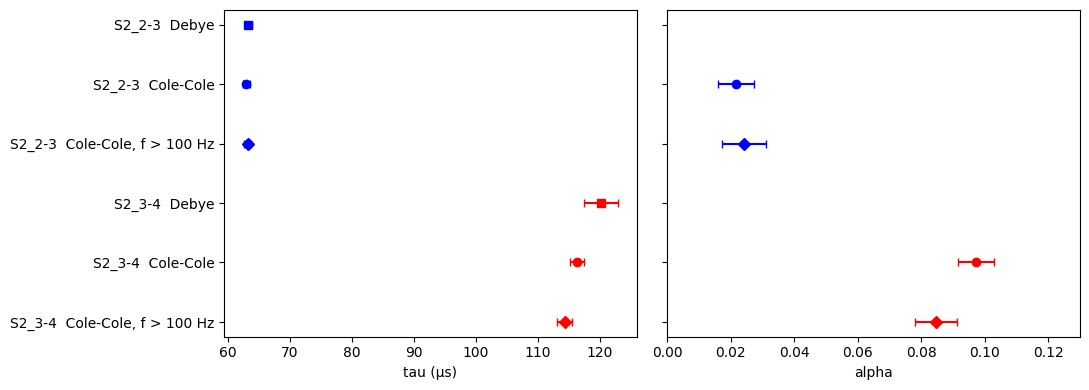

In [25]:
fits = []
for name, color in [("S2_2-3", "blue"), ("S2_3-4", "red")]:
    fits += [
        (f"{name}  Debye", debye_by_name[name], color, "s"),
        (f"{name}  Cole-Cole", cc_by_name[name], color, "o"),
        (f"{name}  Cole-Cole, f > 100 Hz", fil_by_name[name], color, "D"),
    ]

fig, (ax_tau, ax_alpha) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ypos = np.arange(len(fits))[::-1]

for y, (label, r, color, marker) in zip(ypos, fits):
    ax_tau.errorbar(r["tau"] * 1e6, y, xerr=r["sig_tau"] * 1e6,
                    fmt=marker, color=color, capsize=3)
    if "alpha" in r:                      # Debye has no alpha
        ax_alpha.errorbar(r["alpha"], y, xerr=r["sig_alpha"],
                          fmt=marker, color=color, capsize=3)

ax_tau.set_yticks(ypos)
ax_tau.set_yticklabels([f[0] for f in fits])
ax_tau.set(xlabel="tau (µs)")
ax_alpha.set(xlabel="alpha", xlim=(0, 0.13))

fig.tight_layout()
plt.show()

In [36]:
f_qubit = 5e9    # Hz

ext_results = {}
for name in ["S2_2-3", "S2_3-4"]:
    d = debye_by_name[name]
    c = cc_by_name[name]

    debye_model = DebyeCapacitor(d["C_inf"], d["del_C"], d["tau"])
    cc_model = ColeColeCapacitor(c["C_inf"], c["del_C"], c["tau"], c["alpha"])

    # remaining dispersion: C'(5 GHz) - C_inf, as a fraction of del_C
    debye_frac = (debye_model.computeCapacitance(f_qubit) - d["C_inf"]) / d["del_C"]
    cc_frac = (cc_model.computeCapacitance(f_qubit) - c["C_inf"]) / c["del_C"]

    ext_results[name] = {
        "omega_tau_debye": 2 * np.pi * f_qubit * d["tau"],
        "omega_tau_cc": 2 * np.pi * f_qubit * c["tau"],
        "debye_frac": debye_frac,
        "cc_frac": cc_frac,
    }

for name, e in ext_results.items():
    print(f"{name}")
    print("--------------------")
    print(f"omega*tau : {e['omega_tau_debye']:.2e} (Debye)   {e['omega_tau_cc']:.2e} (Cole-Cole)")
    print(f"Debye     : {e['debye_frac']:.2e} of del_C")
    print(f"Cole-Cole : {e['cc_frac']:.2e} of del_C\n")

S2_2-3
--------------------
omega*tau : 1.99e+06 (Debye)   1.98e+06 (Cole-Cole)
Debye     : 2.53e-13 of del_C
Cole-Cole : 2.35e-08 of del_C

S2_3-4
--------------------
omega*tau : 3.78e+06 (Debye)   3.66e+06 (Cole-Cole)
Debye     : 7.02e-14 of del_C
Cole-Cole : 1.81e-07 of del_C



The fractions above, for each sample, represent what part of the slow polarization process keeps up with the field. It is the capacitance above the instantaneous response, divided by the total extra capacitance $\Delta C$:

$$ k = \frac{C'(\omega) - C_\infty}{\Delta C} $$

A fraction of 1 represents the slow polarization keeping up completely with the alternating field, and 0 represents none of it keeping up. At the knee, $\omega \tau = 1$, half of the slow process keeps up. At 5 GHz, however, nearly none of it does: $k$ is about $10^{-13}$ for the Debye model and about $10^{-6}$ for the Cole-Cole model, so the capacitance there is essentially $C_\infty$.

The two models agree on the knee and disagree on the tail. Both place the knee at $\omega\tau = 1$, but above it the remaining dispersion falls as $(\omega\tau)^{-2}$ for Debye and only as $(\omega\tau)^{-(1-\alpha)}$ for Cole-Cole. On a log-log plot these are straight lines of slope $-2$ and about $-0.9$, so an error in the slope grows linearly with the number of powers of ten we extrapolate. Going from the knee (a few kHz) to 5 GHz is about six powers, and a slope difference of about 1.1 turns into about seven orders of magnitude: $k\approx10^{-13}$ for Debye against $10^{-6}$ for Cole-Cole. 

The data does not help us make a clear choice about the slopes. Since the data ends at 20 kHz, only about one order of ten above the knee, where the Debye model leaves about 0.06 nF (S2_2-3) and 0.02 nF (S2_3-4) of dispersion, comparable to the RMS of the fits (about 0.03 nF). Within the Cole-Cole model the fit uncertainty on $\alpha$ is small ($0.007\times6\approx0.04$ decades), so the uncertainty is in the choice of model and not in its parameters. We therefore report the 5 GHz result as a range, and note that only a measurement at higher frequency would narrow it.

## References

[1] S. Khorasani, "CUBIT: Capacitive qUantum BIT," arXiv:1810.08030 (2018).

[2] A. Bezryadin et al., "Large energy storage efficiency of the dielectric layer of graphene nanocapacitors," Nanotechnology 28, 495401 (2017).

[3] A. Rohatgi, WebPlotDigitizer, https://automeris.io (version ?).

[4] S. Karmakar, "Impedance Spectroscopy for Electroceramics and Electrochemical System," arXiv:2406.15467, Sec. 3.3.

[5] F. Kremer and A. Schönhals (eds.), Broadband Dielectric Spectroscopy (Springer, 2003), Ch. 1.

[6] P. Virtanen et al., "SciPy 1.0: fundamental algorithms for scientific computing in Python," Nature Methods 17, 261 (2020).

[7] K. S. Cole and R. H. Cole, "Dispersion and absorption in dielectrics I. Alternating current characteristics," J. Chem. Phys. 9, 341 (1941).